<a href="https://colab.research.google.com/github/suganthavk-ai/Bank-Marketing-Campaign-Analysis/blob/main/Bank_Marketing_Campaign_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

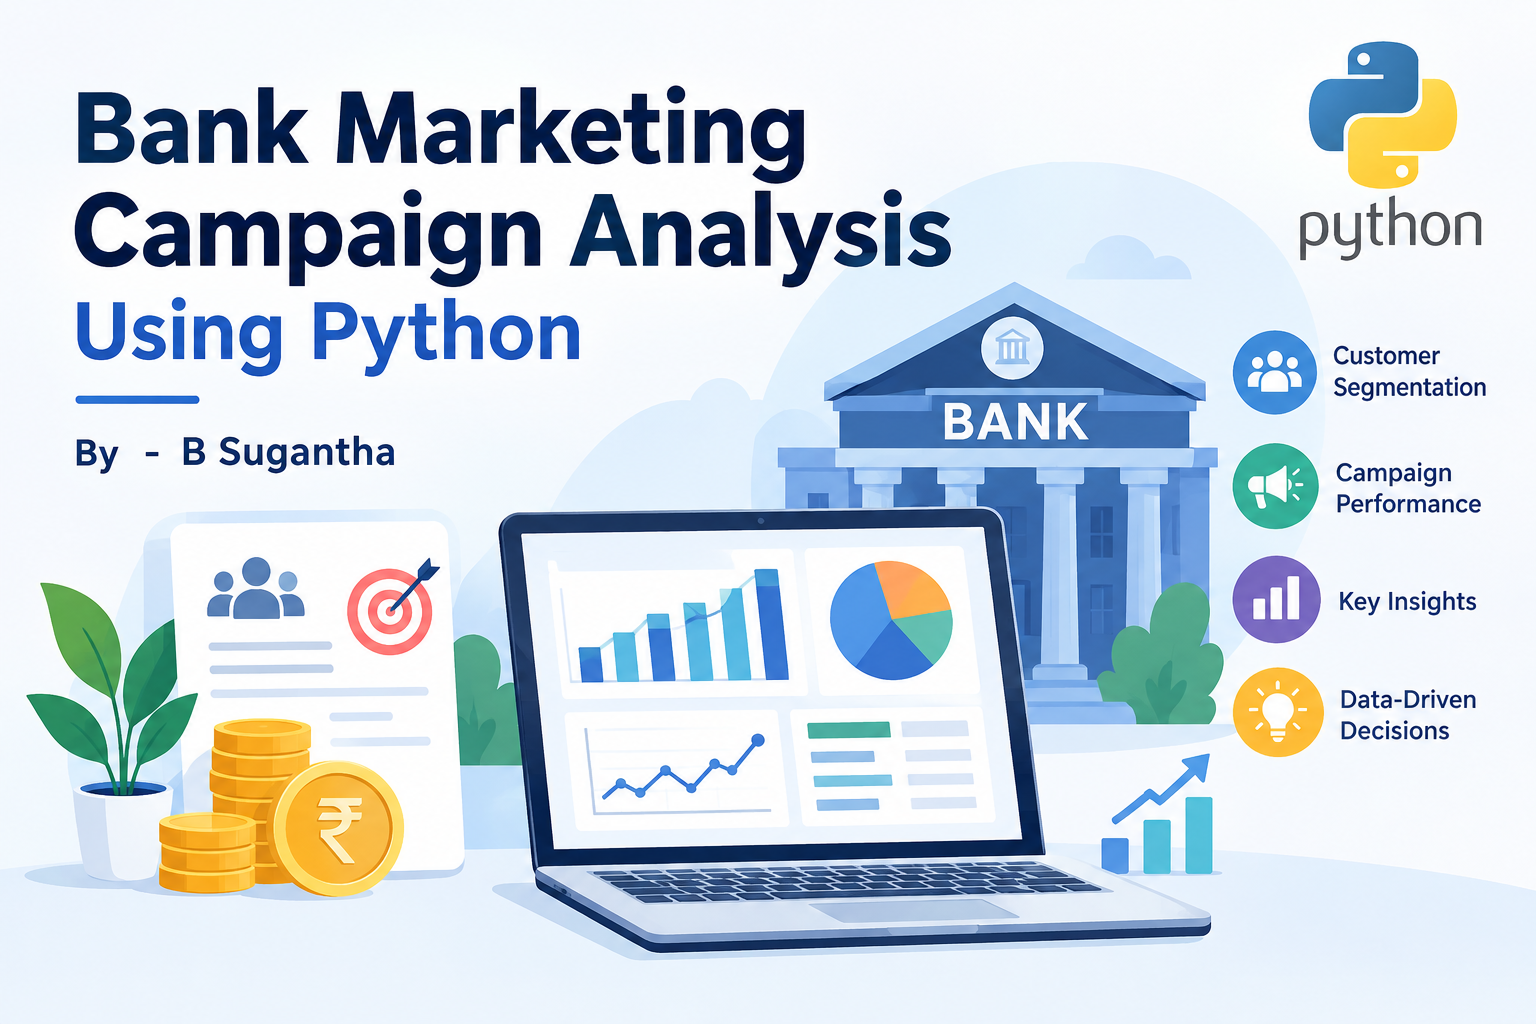

# **Project Title - Bank Marketing Campaign Analysis**

# **Objective**
1. Which customer segments show higher term deposit subscription rates?

2. Which communication method has the highest subscription rate?

3. Does call duration have a relationship with subscription?

4. Does repeated customer contact relate to subscription success?

5. How does previous campaign performance relate to current subscriptions?

6. Which months have better campaign performance?

7. Which customer characteristics are associated with higher subscription rates?

8. What campaign improvements could be investigated based on the findings?

# **Outcome**
Analyze customer demographics, financial characteristics, and marketing campaign performance to understand the factors associated with customers subscribing to bank term deposits.

# **Domain**
1. Title: Bank Marketing  
2. Sources
   Created by: Paulo Cortez (Univ. Minho) and Sérgio Moro (ISCTE-IUL) @ 2012



# **Dataset information**

**Source:** UCI ML Repository

**Link:** https://archive.ics.uci.edu/dataset/222/bank+marketing

**Year / Timeline:** Data collected during 2008 to 2013

**Dataset Column/features Description:**
A data mining approach to predict the success of telemarketing calls for selling bank long-term deposits in Portuguese retail bank was addressed, with data collected from 2008 to 2013, thus including the effects of the recent financial crisis.
Expand

# Bank Client Data:
* **Age** – Customer age

* **Job** – Type of job

* **Marital** – Marital status

* **Education** – Education level

* **Balance** – Average yearly balance

* **Housing** – Housing loan status

* **Loan** – Personal loan status

* **Contact** – Communication method

* **Month** – Contact month

* **Duration** – Last contact duration

* **Campaign** – Number of contacts during the current campaign

* **Pdays** – Days since previous campaign contact

* **Previous** – Number of contacts before the current campaign

* **Poutcome** – Outcome of the previous campaign

* **y** – Current campaign subscription outcome

# **Data Cleaning & Pre-processing**

In [ ]:
# import library

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


**Result explanation:** These libraries provide the tools required to clean the Bank Marketing dataset, perform calculations, analyse customer behaviour and create visualisations.

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/suganthavk-ai/Bank-Marketing-Campaign-Analysis/refs/heads/main/Bank%20Marketing%20Campaign%20Analysis.xlsx"

df = pd.read_excel(url)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


**Result explanation:** The dataset was successfully loaded, and the first five customer records were displayed. The records include customer demographics, financial information, campaign contact details and the subscription outcome.

In [ ]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


**Result explanation:** The last five records were displayed, with row indexes from 45206 to 45210. The dataset contains customer records through index 45210, which is consistent with 45,211 records when indexing starts at zero.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


**Result explanation:**

Total entries: 45,211



Total columns: 17



Numerical columns: 7 (int64)



Categorical/text columns: 10 (object)



Non-null values: 45,211 in every column

All 45,211 rows have non-null values in all 17 columns. This suggests that there are no standard null or missing values in the dataset. However, text values such as "unknown" must be checked separately because Pandas does not automatically treat them as missing values.

In [ ]:
# Number of rows and columns
print("Shape:",df.shape)

Shape: (45211, 17)


**Result Explaination:**

df.shape returns a tuple containing the number of rows and columns. The dataset contains 45,211 rows and 17 columns. Each row represents a customer record, and the columns contain customer attributes and campaign information.
This confirms that the dataset has sufficient records for detailed exploratory data analysis.

In [ ]:
# Column Names
print("\nColumns:")
print(df.columns.tolist())


Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


**Result Explanation:**
- "\nColumns:" prints a heading on a new line. \n represents a newline character.
- df.columns retrieves the column names.
- .tolist() converts the column index into a regular Python list.

- All 17 column names were identified. The columns cover demographic details, account balance, loan information, contact history and the campaign's final subscription outcome.

In [ ]:
# Column Types
print("\nData Type:")
print(df.dtypes)


Data Type:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


**Result Explaination:**

- **Integer-valued numerical data(int64):**	age, balance, day, duration, campaign, pdays, previous

- **Text or categorical data(Object):** job, marital, education, default, housing, loan, contact, month, poutcome, y

- df.dtypes returns the data type of each column.

- int64 represents integer-valued data.

- Object commonly represents text or categorical values in Pandas.
 The columns have data types suitable for the initial analysis. Numerical columns can be used for statistical calculations, while categorical columns can be used to analyse customer groups and subscription outcomes. No data type conversion is required at this initial stage based on the displayed output.

In [ ]:
# Basic statistical summary
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


**Result Explanation:**
df.describe() calculates summary statistics for numerical columns by default.
- count: Number of non-null observations.
- mean: Average value.
- std: Standard deviation, indicating how spread out the values are.
- min: Minimum value.
- 25%: First quartile.
- 50%: Median.
- 75%: Third quartile.
- max: Maximum value.

- The ***average customer*** age is approximately ***41 years***, the ***average account balance is 1,362.27***, and the ***average call duration*** is about ***258 seconds***.

- The large differences between the median and maximum values for ***balance and duration*** suggest that these variables may contain extreme values and could be ***right-skewed.***


In [ ]:
# Check missing values
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


**Result Explaination:**

- All 17 columns returned 0.

- df.isnull() checks each cell for a standard missing value, such as NaN.
- .sum() counts the missing values column by column.
- No standard null values were found in any column. Therefore, there is no immediate need to impute or remove records because of standard missing values.
- The text value **"unknown"** is not the same as a null value. It needs a separate check.

In [ ]:
# Count unknown values
for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(col, ":", count)

job : 288
education : 1857
contact : 13020
poutcome : 36959


**Result Explaination:**
- The job, education, contact and poutcome columns contain unknown values. The largest count is in poutcome, with 36,959 records.
- These values are being retained as a separate category instead of automatically being treated as missing data.
- This allows you to investigate whether unavailable information is associated with campaign outcomes.

In [ ]:
# Duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Result Explaination:**
- No fully duplicated records were identified. Therefore, no rows were removed during duplicate handling.
- This checks for identical rows, not whether the same customer appears multiple times under different records.

In [ ]:
# rename y to subscription:
df.rename(columns={"y": "subscription"}, inplace=True)
df["subscription"].value_counts()

,count
subscription,
no,39922
yes,5289


**Result Explanation:**
- df.rename() renames a column.
- columns={"y": "subscription"} specifies the old and new column names.
- inplace=True modifies the existing DataFrame directly.
- df["subscription"] selects the renamed column.
- .value_counts() counts the occurrences of each distinct value.
Result interpretation: Out of 45,211 records, 39,922 customers did not subscribe to the term deposit, while 5,289 customers subscribed.
- The subscription rate is approximately 11.70%, while the non-subscription rate is approximately 88.30%. This indicates that the dataset contains substantially more non-subscribing customers than subscribing customers.
- Renaming y to subscription makes the target column easier to understand in subsequent analysis.

In [ ]:
# Data types

# Numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns
print("Numerical columns:")
print(numeric_columns)

Numerical columns:
Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')


**Result Explanation:**
- include=np.number selects columns containing numerical data types.
- .columns retrieves their names.
- numeric_columns stores the selected column names in a variable.
- print() displays the result.
- Seven numerical columns were identified. These variables can be used for statistical summaries, outlier detection, distributions and numerical comparisons.

In [ ]:
# Categorical columns
categorical_columns = df.select_dtypes(include="object").columns
print("\nCategorical columns:")
print(categorical_columns)


Categorical columns:
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'subscription'],
      dtype='object')


**Result Explanation:**
- This code selects columns with the object data type and stores their names in categorical_columns.
- The categorical columns represent customer characteristics, financial product indicators, contact details, campaign outcomes and the subscription target.
- They are useful for comparing subscription rates across customer groups.

In [ ]:
# Treat outliers

Q1 = df["balance"].quantile(0.25)
Q3 = df["balance"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["balance"] < lower) |
    (df["balance"] > upper)
]

len(outliers)

**Result Explanation:**

- df["balance"]	Selects the account balance column.
- .quantile(0.25)	Calculates the first quartile (Q1).
- .quantile(0.75)	Calculates the third quartile (Q3).
- IQR = Q3 - Q1	Calculates the interquartile range.
- Q1 - 1.5 * IQR	Calculates the lower outlier boundary.
- Q3 + 1.5 * IQR	Calculates the upper outlier boundary.
- df[...]	Filters rows matching the specified conditions.
\|	Means OR when combining the two Pandas conditions.
- len(outliers)	Counts the rows identified as outliers.

**Expected boundaries from your statistical summary**
- reports \[Q1 = 72 and Q3 = 1,428]  
for **balance.**

\[
IQR = 1428 - 72 = 1356
\]

\[
{Lower boundary} = 72 - 1.5(1356) = -1962
\]

\[
{Upper boundary} = 1428 + 1.5(1356) = 3462
\]

- Balances below − 1,962 or above 3,462 are flagged as potential outliers.
- The IQR method identifies unusually low or high account balances for further investigation. An outlier is not automatically an error: a high balance could represent a genuine customer account.


# **EDA & Visualizations**

**1. Analyze the target variable (Subscription)**

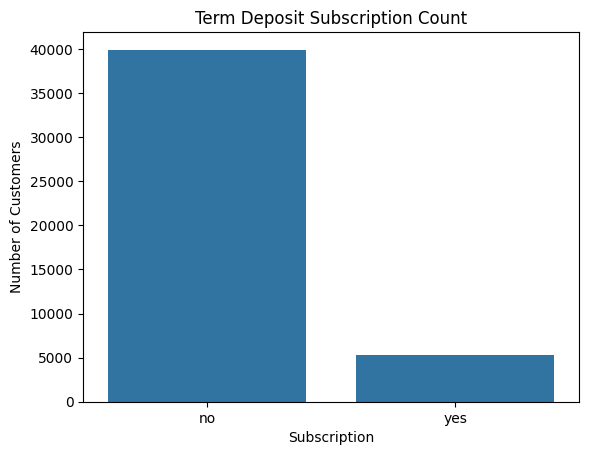

In [ ]:
df["subscription"].value_counts()

sns.countplot(data=df, x="subscription")
plt.title("Term Deposit Subscription Count")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

**Syntax explanation:**
- df["subscription"] selects the subscription column.
- .value_counts() counts how many customers belong to each category.
- sns.countplot() creates a bar chart showing the number of customers in each category.
- plt.title() adds a title to the chart.
- plt.xlabel() and plt.ylabel() label the axes.
- plt.show() displays the chart.

**Result explanation:**
The dataset contains 39,922 customers who did not subscribe and 5,289 customers who subscribed to a term deposit. Approximately 11.7% of customers subscribed, while 88.3% did not.

**Conclusion for your project:** The campaign has a relatively low subscription rate. The bank could investigate which customer groups and campaign strategies are associated with higher subscription rates.

**2. Univariate analysis — Customer age distribution**

This analysis helps us understand the age profile of customers contacted by the bank.

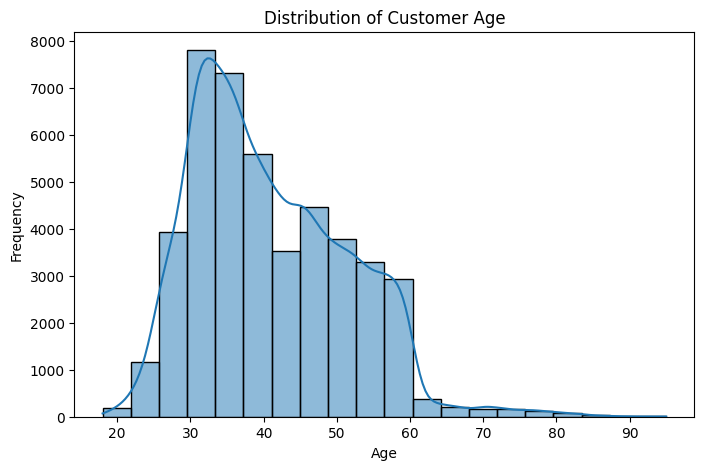

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

**Syntax Explanation:**
- plt.figure(figsize=(8, 5)) sets the chart size.
- sns.histplot() displays the frequency distribution of ages.
- x="age" selects the age column.
- bins=20 divides the age range into 20 intervals.
- kde=True adds a smooth curve to help show the distribution pattern.
- plt.xlabel() and plt.ylabel() label the axes.

**Result Explanation:**

- The average customer age is approximately 40.94 years, the median is 39 years, and the age range is 18–95 years.
- The histogram will show which age ranges contain the most customers. This helps the bank understand the age profile of its campaign audience.

**Project Conclusion:** Customers in different age groups can be compared to determine which groups have higher term deposit subscription rates. The age distribution alone does not identify the most successful group.

**3. Numerical analysis — Bank balance distribution**

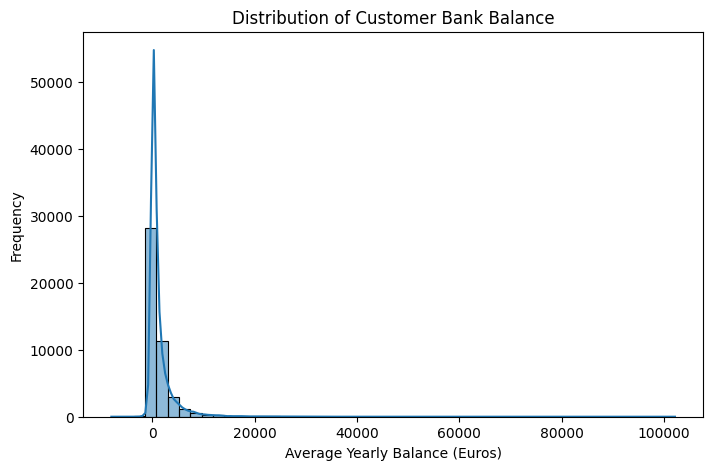

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="balance", bins=50, kde=True)

plt.title("Distribution of Customer Bank Balance")
plt.xlabel("Average Yearly Balance (Euros)")
plt.ylabel("Frequency")
plt.show()

**Syntax Explanation:**
- x="balance" selects customers' bank balance values.
- bins=50 divides the balance range into 50 intervals.
- kde=True adds a smoothed distribution curve.
- The remaining commands set the chart title, axis labels, and display the chart.

**Result explanation:**
- An average balance of approximately 1,362.27 and a median balance of 448. The maximum balance is 102,127, while the minimum is −8,019.
- The large difference between the mean and median suggests that high balance values may pull the average upward.
- The histogram can help reveal whether the distribution is right-skewed.

**Project Conclusion:** Customer balances vary considerably. The bank can investigate whether balance levels are associated with subscription success. Extreme balances should be checked before deciding whether they require treatment.

**4. Categorical analysis — Customers by job type**

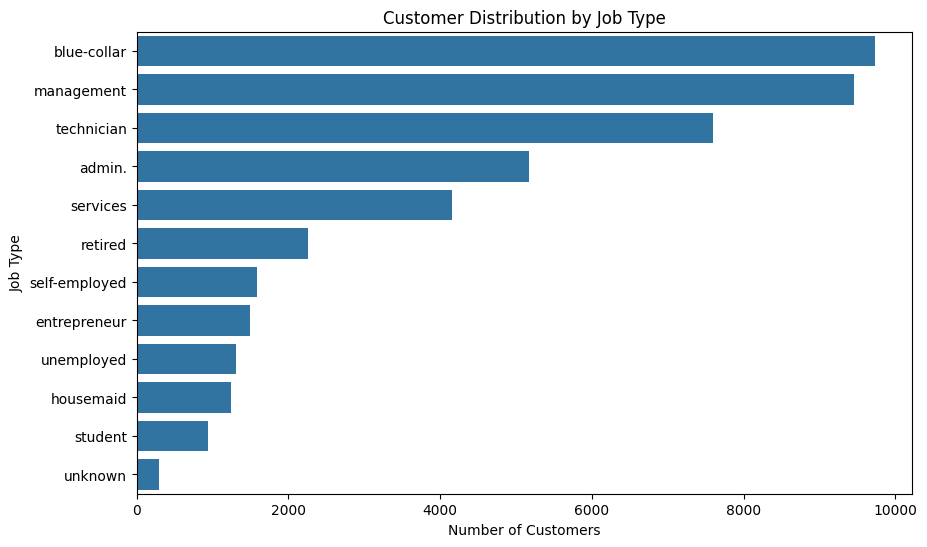

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="job",
    order=df["job"].value_counts().index
)

plt.title("Customer Distribution by Job Type")
plt.xlabel("Number of Customers")
plt.ylabel("Job Type")
plt.show()

**Syntax Explanation:**
- y="job" displays job categories on the vertical axis.
- order=df["job"].value_counts().index arranges the categories from the most frequent to the least frequent.
- y="job" makes the labels easier to read when category names are long.
- sns.countplot() counts the records in each job category.

**Result Explanation:**
The bar chart shows how customers are distributed across occupations. The longest bar represents the job category with the highest number of customers, while the shortest represents the least frequent category.

**Project conclusion:** This chart identifies the bank's most frequently contacted occupational groups. To find which occupation responds best, we must compare subscription rates rather than customer counts alone.

**5. Bivariate analysis — Subscription rate by job type**

This is more useful than simply counting customers because it compares campaign outcomes across occupations.

In [ ]:
job_rate = (
    df.groupby("job")["subscription"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print(job_rate)

job
student          28.678038
retired          22.791519
unemployed       15.502686
management       13.755551
admin.           12.202669
self-employed    11.842939
unknown          11.805556
technician       11.056996
services          8.883004
housemaid         8.790323
entrepreneur      8.271688
blue-collar       7.274969
Name: subscription, dtype: float64


**Syntax Explanation:**
- groupby("job") groups records by occupation.
- ["subscription"] selects the campaign outcome.
- lambda x: (x == "yes").mean() * 100 calculates the percentage of customers who subscribed within each group.
- .sort_values(ascending=False) sorts the rates from highest to lowest.
- print(job_rate) displays the percentages.

**Result Explanation:**
The output gives one subscription percentage for each job category. The first category has the highest observed subscription rate, and the last has the lowest.

**Project conclusion:** The results help identify occupations that may be promising target groups for future campaigns. However, the number of customers in each group should also be considered.

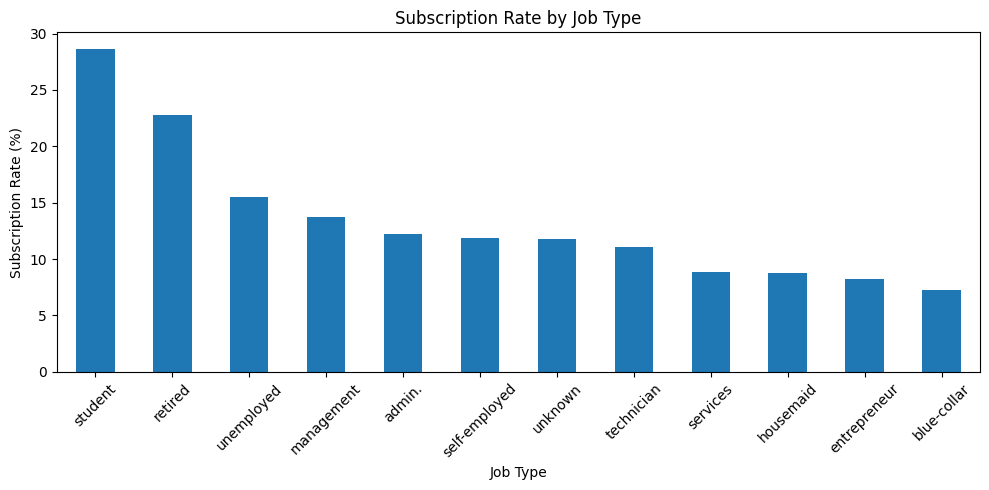

In [ ]:
job_rate.plot(kind="bar", figsize=(10, 5))

plt.title("Subscription Rate by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Syntax Explanation:**

- .plot(kind="bar") creates a bar chart from the calculated rates.

- rotation=45 tilts the category labels for readability.

- plt.tight_layout() reduces overlapping labels.

**6. Analyze subscription rate by communication method**

In [ ]:
contact_rate = (
    df.groupby("contact")["subscription"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

print(contact_rate)

contact
cellular     14.918900
telephone    13.420509
unknown       4.070661
Name: subscription, dtype: float64


**Syntax Explanation:**
- groupby("contact") groups customers by communication method.
- .apply() calculates a subscription rate for each method.
- (x == "yes") identifies successful subscriptions.
- .mean() * 100 converts the proportion of successful subscriptions into a percentage.
- .sort_values(ascending=False) ranks the methods by subscription rate.

**Result Explanation:**
- The output compares the percentage of customers who subscribed after being contacted through each available communication method, including cellular, telephone, and unknown.

- The method with the highest percentage has the highest observed subscription rate in this dataset. The actual ranking must be confirmed by running the code.

**Project conclusion:** The bank can compare communication methods to identify which ones are associated with better campaign outcomes. A high subscription rate does not necessarily mean that a method produces the largest number of subscriptions.

**7. Analyze call duration and subscription**

This analysis investigates whether call duration is associated with subscription success.

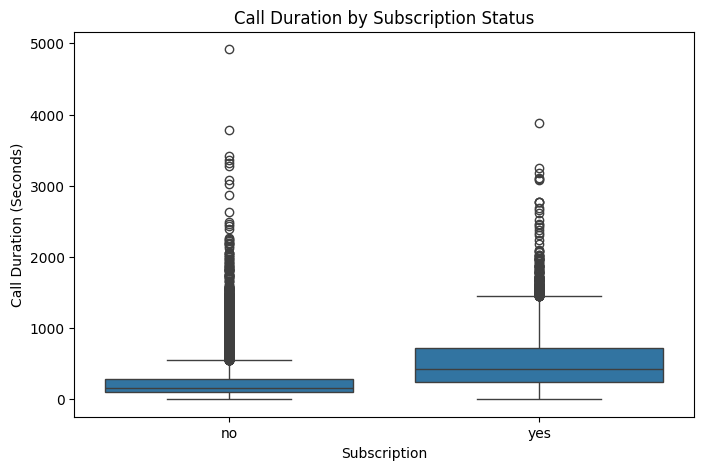

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="subscription", y="duration")

plt.title("Call Duration by Subscription Status")
plt.xlabel("Subscription")
plt.ylabel("Call Duration (Seconds)")
plt.show()

**Syntax Explanation:**
- x="subscription" separates customers into subscribed and not-subscribed groups.
- y="duration" compares their call durations.
- sns.boxplot() displays the median, quartiles, spread, and potential outliers for each group.
Result explanation
Compare the two boxplots:
- The line inside each box represents the median call duration.
- The box represents the middle 50% of call durations.
- The whiskers show the range according to the boxplot's outlier rule.
- Points beyond the whiskers represent potential outliers.

If the *yes* group has a higher median duration, that suggests successful subscriptions are associated with longer calls in this dataset.

**Project Conclusion:**
Call duration may be an important indicator of campaign outcomes. However, longer calls do not prove that longer conversations cause customers to subscribe.

**Note:**
That duration is known only after the call has taken place. It should be used carefully when building models intended to predict subscription before a call.

**8. Analyze subscription rate by campaign contact frequency**

The campaign column represents the number of contacts made during the current campaign for a customer.

In [ ]:
campaign_rate = (
    df.groupby("campaign")["subscription"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

print(campaign_rate.head(15))

campaign
1     14.597583
2     11.203519
3     11.193624
4      9.000568
5      7.879819
6      7.126259
7      6.394558
8      5.925926
9      6.422018
10     5.263158
11     7.960199
12     2.580645
13     4.511278
14     4.301075
15     4.761905
Name: subscription, dtype: float64


**Syntax Explanation:**
- groupby("campaign") groups customers by the number of contacts.
- .apply() calculates the subscription rate within each group.
- .head(15) displays the first 15 rows of the resulting series.

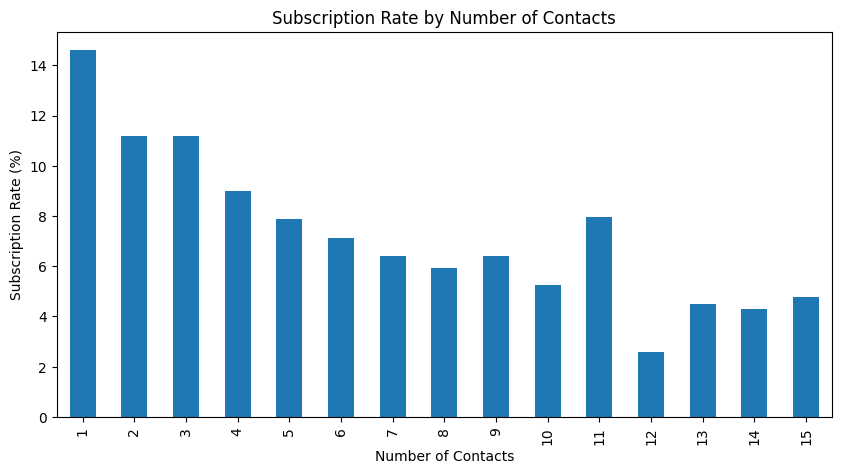

In [ ]:
campaign_rate.head(15).plot(kind="bar", figsize=(10, 5))

plt.title("Subscription Rate by Number of Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.show()

**Result Explanation:**
The output shows how subscription rates vary with the number of contacts. If rates decline as contact frequency increases, repeated contact may be associated with lower subscription success.

**Project conclusion:**
The bank can investigate whether repeated contacts are associated with better or worse outcomes and review its contact strategy. Be careful with groups containing very few customers, as their rates can fluctuate substantially.

**9. Analyze subscription rate by month**

In [ ]:
month_rate = (
    df.groupby("month")["subscription"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

print(month_rate)

month
apr    19.679400
aug    11.013286
dec    46.728972
feb    16.647792
jan    10.121169
jul     9.093546
jun    10.222805
mar    51.991614
may     6.719454
nov    10.151134
oct    43.766938
sep    46.459413
Name: subscription, dtype: float64


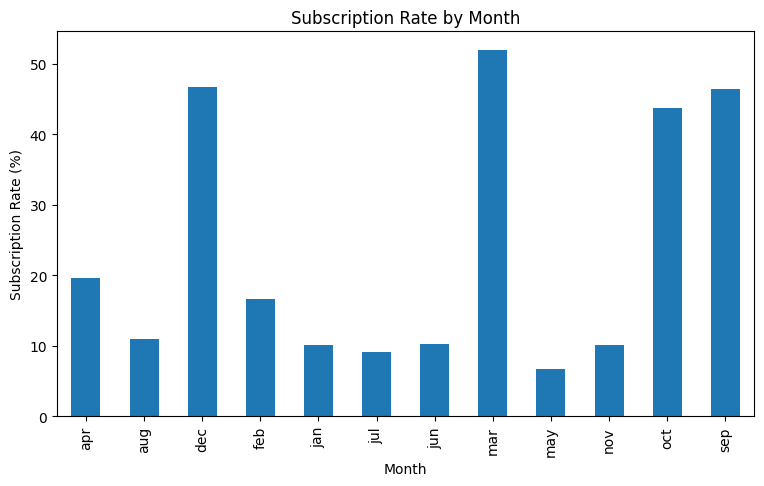

In [ ]:
month_rate.plot(kind="bar", figsize=(9, 5))

plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.show()

**Syntax Explanation:**
- groupby("month") groups records by the month in which the campaign contact occurred.
- .apply(lambda x: ...) calculates the percentage of subscriptions in each month.
- .plot(kind="bar") displays a bar chart for comparing the monthly rates.

**Result Explanation:**
The chart compares the subscription rate across the months represented in the dataset. The tallest bar indicates the month with the highest observed subscription rate, and the shortest indicates the lowest.

**Project conclusion:** The bank can investigate seasonal patterns and identify months worth studying for future campaigns. This chart measures subscription rates, not total subscriptions or campaign profitability.

**10. Correlation analysis of numerical variables**

Correlation can help identify relationships between numerical variables, such as age, balance, duration, campaign contacts, and previous contacts.

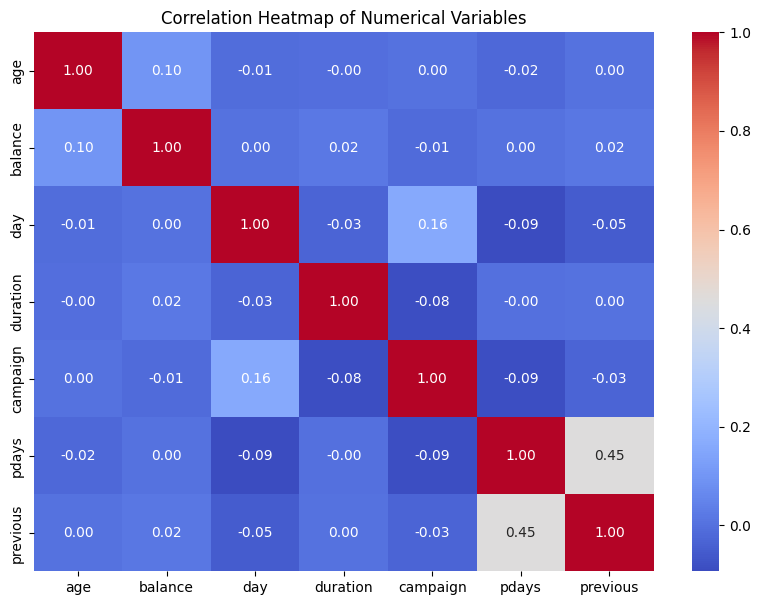

In [ ]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

**Syntax Explanation:**
- select_dtypes(include="number") selects numerical columns.
- .corr() calculates pairwise Pearson correlation coefficients.
- sns.heatmap() represents the correlation matrix using colours.
- annot=True displays the correlation values inside the cells.
- cmap="coolwarm" selects a colour palette.
- fmt=".2f" formats displayed values to two decimal places.

**Result explanation:**
- Correlation values range from −1 to +1:
- Close to +1 - Strong positive linear relationship
- Close to 0 - Little or no linear relationship
- Close to −1	- Strong negative linear relationship
- The heatmap helps identify numerical variables that move together. Correlation does not establish causation.

**Important:** The subscription column is categorical, so it will not appear in this numerical correlation matrix. To analyze subscription directly, use the group-based rate calculations above or an appropriate statistical method.